# Project Description Phase 1

Consider the following (hypothetical) scenario: for the latest local election, an unnamed country decided to experiment with electoral technologies and to provide the possibility of casting a vote online for voters in a selected municipality. The rest of the voters voted on paper in their polling stations, as usual. The results of the election have shown that the votes cast electronically were distributed differently than the votes cast on paper. In order to investigate the possibility of election manipulation, as well as to study the demographics of voters who decided to cast their vote online, a survey was conducted (date of data collection 1/7/2025). For the sake of transparency, the statistical agency conducting the survey decided to release the results to the public. However, due to sensitive nature of the survey (in particular, the political preferences of the voters), the released dataset had to be anonymised beforehand.

In this project you will take the role of both the statistical agency (the anonymisers) and the adversary who attempts to learn the political preferences of the population from the released dataset (the deanonymisers). The project would therefore consist of two phases.

The submissions in both phases of the project will occur in groups, with only one submission per group. The submissions will be done using the Peer feedback activity.

Phase 1

You will receive the following files (in all the file names, X stands for the letter assigned to your group):

"private_dataX.xlsx" as the raw (i.e. non-anonymised) survey data,
"public_data_registerX.xlsx" as the public population register,
"public_data_resultsX.xlsx" as the published results of the election.
A description of the attributes in the datasets (same for all the groups) is furthermore available in the appendix at the bottom.

Your tasks during the first phase will be:

Step 1: Analyse the data in the raw dataset answering the following questions (note, you are free to choose the suitable methods of the analysis yourself, based on your knowledge of e.g. applied statistics or other courses of your study):

(A) Is there a significant difference between the political preferences as expressed in the survey and the election results for both electronic and polling station votes?

(B) Is there a significant difference between political preferences of the voters depending on their demographic attributes recorded in the survey (that is, age, gender, education level…)?

(C) Is there a significant difference between voter’s choice of the voting channel (that is, if they decide to vote either online or in person) depending on their demographic attributes recorded in the survey?

Step 2: Anonymise the raw dataset and calculate the disclosure risks (you can use any suitable metrics, e.g. among these that were discussed in the course or presented in optional readings). In these calculations, assume that your anonymised dataset, the public data (that is, the files public_data_registerX.xslx and public_data_resultsX.xslx) as well as your submitted report (see Step 4 below) will be available to a potential adversary, but no other data will be available.

Step 3: Conduct the same analyses as in Step 1, but this time on the anonymised dataset. Note the differences in the analysis outcome compared to the analyses you have performed on raw dataset. If the differences are too large (according to your own evaluation), return to Step 2 and redo the anonymisation.

Step 4: Write a report describing:

The methods you used to anonymise the dataset in Step 2. You can use the external reports from the case studies here: https://sdcpractice.readthedocs.io/en/latest/appendices.html#case-study-1-external-report as examples.
The disclosure risk metrics you calculated in Step 2. Note, depending on the metrics you used, reporting on them might reveal additional information about the dataset; in that case, feel free to omit details to prevent such disclosure.
The results of the analyses conducted in Step 3.
Your own reflections on whether the trade-off between disclosure risk you achieved and the utility losses (i.e. the difference between the analyses conducted in Step 1 and Step 3) is good enough. Note, you don’t have to include the actual results of the Step 1 analyses in the report.
Your report should be at most 10 pages long, using 12pt font size.

How to submit: Your submission should consist of the following files, uploaded as an attachments in the Peer feedback activity:

(a) the anonymised dataset as a .csv file named "anonymised_dataX.csv" with X as the letter assigned to your group

(b) the report as a PDF file named “reportX.pdf” with X as the letter assigned to your group

The deadline for the submission of the first phase results is Friday, November 6th, 23:59.

# Step 0

### Exploratory Data Analysis

In [1]:
import pandas as pd
from pathlib import Path

# Path to data folder
DATA_DIR = Path("../data/H")

# Read Excel files
private_data = pd.read_excel(DATA_DIR / "private_dataH.xlsx")
public_register = pd.read_excel(DATA_DIR / "public_data_registerH.xlsx")
public_results = pd.read_excel(DATA_DIR / "public_data_resultsH.xlsx")

In [2]:
for name, df in {
    "Private Survey": private_data,
    "Public Register": public_register,
    "Election Results": public_results
}.items():
    print(f"\n{'='*50}")
    print(name)
    print(f"{'='*50}")
    print(f"Shape: {df.shape}")
    display(pd.DataFrame({
        "dtype": df.dtypes,
        "missing": df.isna().sum(),
        "unique": df.nunique()
    }))
    display(df.head())


Private Survey
Shape: (200, 9)


,dtype,missing,unique
name,object,0,200
sex,object,0,2
evote,int64,0,2
dob,datetime64[ns],0,198
zip,int64,0,4
education,object,0,9
citizenship,object,0,18
marital_status,object,0,4
party,object,0,3


,name,sex,evote,dob,zip,education,citizenship,marital_status,party
0,"al-Hasan, Saami",Male,1,1957-07-22,2400,Primary education,Denmark,Married/separated,Green
1,"el-Azzam, Urwa",Female,0,1992-06-11,2400,Vocational Education and Training (VET),Denmark,Never married,Green
2,"al-Fayad, Laaiqa",Female,1,1991-07-28,2100,Masters programmes,Denmark,Never married,Red
3,"al-Nawaz, Mushtaaqa",Female,0,1963-04-25,2100,Primary education,Denmark,Married/separated,Green
4,"el-Abbasi, Fat'hiyaa",Female,0,1974-06-14,2300,Vocational bachelors educations,Denmark,Married/separated,Red



Public Register
Shape: (1494, 7)


,dtype,missing,unique
name,object,0,1494
sex,object,0,2
dob,datetime64[ns],0,1448
zip,int64,0,4
citizenship,object,0,52
marital_status,object,0,4
last_voted,int64,0,3


,name,sex,dob,zip,citizenship,marital_status,last_voted
0,"al-El-Sayed, Naadir",Male,2000-03-21,2200,Denmark,Never married,2
1,"Willingham, Daravion",Male,2001-01-26,2200,Denmark,Never married,2
2,"Manchego, Alisa",Female,2003-04-07,2100,Denmark,Never married,1
3,"Gildon, Brittany",Female,2004-12-28,2400,Denmark,Never married,1
4,"Ruybal, Morgan",Female,2000-09-04,2300,Denmark,Never married,1



Election Results
Shape: (6, 5)


,dtype,missing,unique
Unnamed: 0,object,0,6
Red,int64,0,6
Green,int64,0,6
Invalid ballots,int64,0,6
Total,int64,0,6


,Unnamed: 0,Red,Green,Invalid ballots,Total
0,Polling station: ZIP 2100,30,72,4,106
1,Polling station: ZIP 2200,49,99,3,151
2,Polling station: ZIP 2300,83,81,1,165
3,Polling station: ZIP 2400,95,153,5,253
4,E-votes,123,238,10,371


In [3]:
missing = pd.DataFrame({
    "Missing": private_data.isna().sum(),
    "Percentage": (private_data.isna().mean() * 100).round(2)
})

display(missing.sort_values("Percentage", ascending=False))

,Missing,Percentage
name,0,0.0
sex,0,0.0
evote,0,0.0
dob,0,0.0
zip,0,0.0
education,0,0.0
citizenship,0,0.0
marital_status,0,0.0
party,0,0.0


In [4]:
categorical_cols = private_data.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in categorical_cols:
    print(f"\n{col}")
    display(
        private_data[col]
        .value_counts(dropna=False)
        .to_frame("Count")
    )


name


,Count
name,
"al-Hasan, Saami",1
"Marks, Courtney",1
"Nguyen, Ritika",1
"Gutierrez, Joseph",1
"el-Amber, Aqeela",1
...,...
"Nguyen, Tyler",1
"Rodriguez, Jason",1
"Rivera, Kylina",1



sex


,Count
sex,
Female,103
Male,97



education


,Count
education,
Vocational Education and Training (VET),66
Primary education,46
Vocational bachelors educations,36
Masters programmes,23
Upper secondary education,13
Short cycle higher education,8
Bachelors programmes,4
Not stated,2
PhD programmes,2


... (2 outputs left out)


marital_status


,Count
marital_status,
Married/separated,88
Never married,76
Divorced,27
Widowed,9



party


,Count
party,
Green,131
Red,66
Invalid vote,3


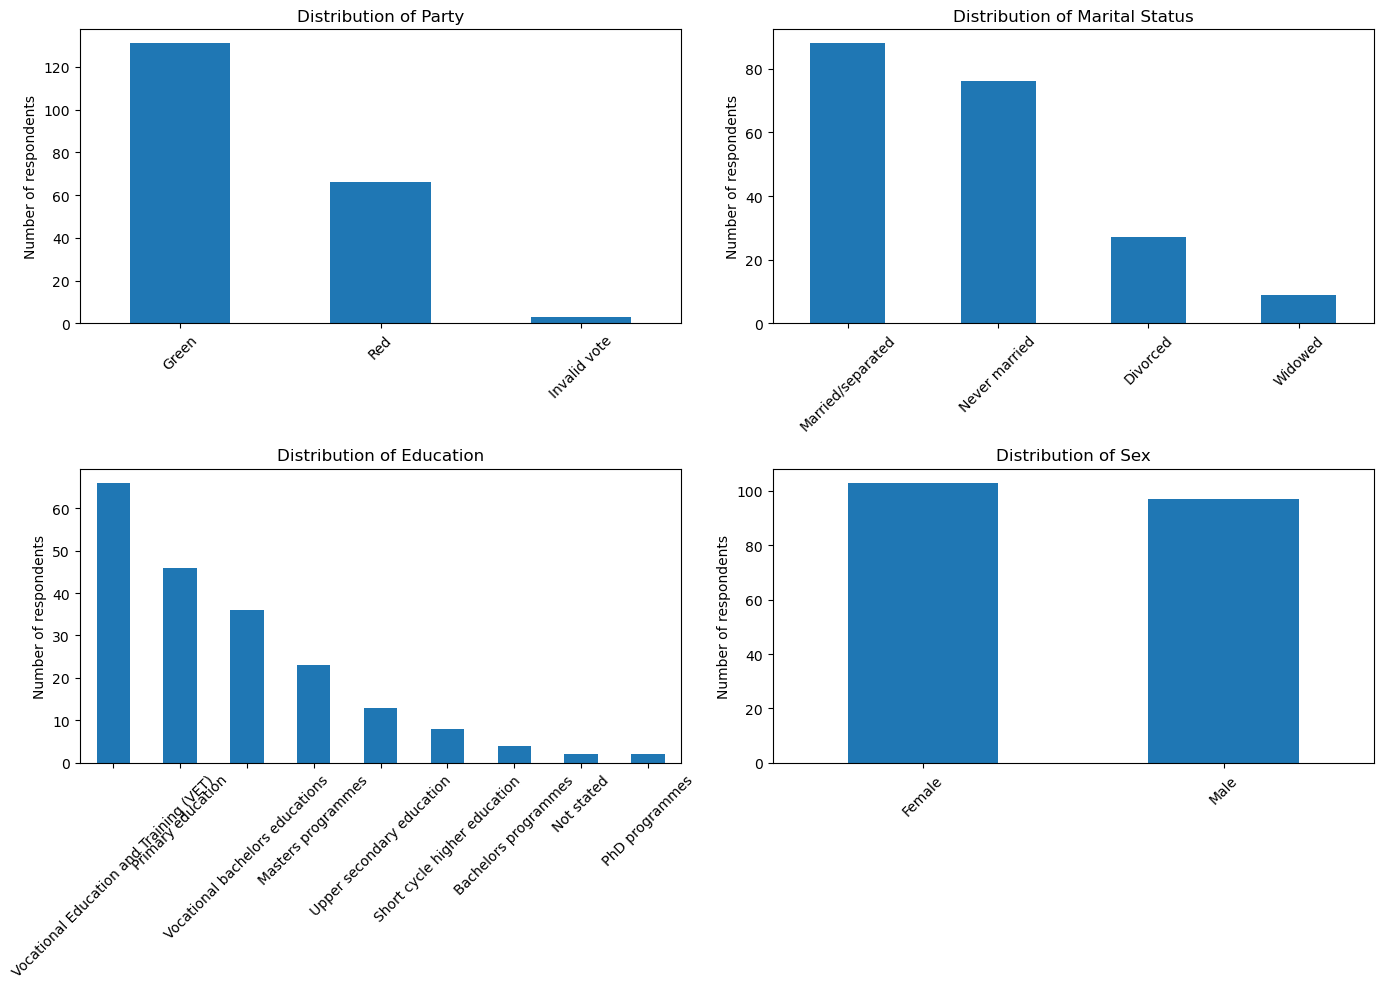

In [5]:
import matplotlib.pyplot as plt

columns = ["party", "marital_status", "education", "sex"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flatten(), columns):
    counts = private_data[col].value_counts(dropna=False)

    counts.plot(kind="bar", ax=ax)

    ax.set_title(f"Distribution of {col.replace('_', ' ').title()}")
    ax.set_xlabel("")
    ax.set_ylabel("Number of respondents")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [10]:
print("Duplicate rows:", private_data.duplicated().sum())

Duplicate rows: 0
